# Comparativa de emociones: YOLO11s-cls vs Eigenfaces + SVM vs DeepFace

Se comparan los tres clasificadores de emociones del proyecto con las **mismas entradas**:

| Modelo | Origen | Entrada |
|---|---|---|
| **YOLO11s-cls** | Entrenado en `emotion_detector.ipynb` | Recorte BGR, reescalado a 48x48 |
| **Eigenfaces + SVM** | Entrenado en `VC_P5_eigenfaces_emociones.ipynb` (`models/eigenfaces_svm.joblib`) | Recorte en gris de 48x48 → PCA → SVM |
| **DeepFace** | `DeepFace.analyze(actions=['emotion'])`, modelo preentrenado | Recorte BGR (internamente lo pasa a gris de 48x48) |

Las 7 clases de `dataset_emociones` (FER-2013) se llaman igual que las claves de `emotion` de DeepFace, así que no hace falta traducir etiquetas.

Hay dos comparaciones:
1. **Cuantitativa** sobre las 7.178 imágenes de `dataset_emociones/test`, que ni YOLO ni el SVM han visto al entrenar.
2. **En tiempo real** con la webcam: el detector YOLO11s localiza la cara y el mismo recorte se pasa a los tres modelos. Se puede indicar con el teclado la emoción que se está poniendo para medir el acierto con caras reales.

**Notas importantes**
- En DeepFace se usa `detector_backend='skip'`: las caras ya vienen recortadas (por FER-2013 o por el detector YOLO). Así se compara solo el **clasificador**, no el detector.
- El modelo de emoción de DeepFace **también está entrenado con FER-2013**. Es posible que parte de las imágenes de test se usaran para validar ese modelo, así que su resultado en test puede ser algo optimista. La prueba con webcam no tiene este problema.
- El SVM se entrenó sin `probability=True`, así que no da confianza, solo la etiqueta.

## C.1 Carga de los modelos

In [1]:
# ===== C.1.1 Carga de los tres clasificadores de emociones y del detector de caras =====
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"       # evita el error de OpenMP duplicado en Windows
from pathlib import Path
from time import perf_counter

import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from deepface import DeepFace
from ultralytics import YOLO
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

from utils import LoadDataset, abrir_camara, dibujar_texto

TEST_DIR = Path("dataset_emociones/test")
SVM_PATH = Path("models/eigenfaces_svm.joblib")
YOLO_CLS_PATH = Path("runs/classify/yolo11s-cls_emotion_detector/weights/best.pt")
YOLO_DET_PATH = Path("runs/detect/yolo11s_face_detector/weights/best.pt")

# --- Eigenfaces + SVM (pipeline PCA -> MinMaxScaler -> SVC) ---
guardado = joblib.load(SVM_PATH)
svm = guardado["modelo"]
CLASES = guardado["clases"]
W_CARA, H_CARA = guardado["width"], guardado["height"]     # 48x48, como FER-2013

# --- YOLO11s-cls (emociones) y YOLO11s (caras, solo para la demo) ---
yolo_cls = YOLO(YOLO_CLS_PATH)
detector = YOLO(YOLO_DET_PATH)
assert sorted(yolo_cls.names.values()) == sorted(CLASES), "YOLO y el SVM no tienen las mismas clases"

# --- DeepFace: una primera llamada carga el modelo (y descarga los pesos la primera vez) ---
DeepFace.analyze(np.zeros((H_CARA, W_CARA, 3), np.uint8), actions=["emotion"],
                 detector_backend="skip", enforce_detection=False, silent=True)

IDX = {c: i for i, c in enumerate(CLASES)}
print("Clases:", CLASES)


Clases: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [2]:
# ===== C.1.2 Funciones de predicción con la misma interfaz para los tres modelos =====
# Reciben una lista de recortes de cara en BGR y devuelven (índices de clase, confianzas).

def predecir_yolo(caras):
    res = yolo_cls(caras, imgsz=W_CARA, verbose=False)
    return [IDX[r.names[r.probs.top1]] for r in res], [float(r.probs.top1conf) for r in res]


def predecir_svm(caras):
    # Mismo preprocesado que en el entrenamiento: gris, 48x48, vector de float32
    X = np.stack([cv2.resize(cv2.cvtColor(c, cv2.COLOR_BGR2GRAY), (W_CARA, H_CARA),
                             interpolation=cv2.INTER_AREA).reshape(-1) for c in caras]).astype(np.float32)
    return svm.predict(X).astype(int).tolist(), [None] * len(caras)    # SVC sin probability: sin confianza


def predecir_deepface(caras):
    res = DeepFace.analyze(list(caras), actions=["emotion"], detector_backend="skip",
                           enforce_detection=False, silent=True)
    # Con una lista de imágenes devuelve una lista por imagen (y dentro, una entrada por cara)
    res = [r[0] if isinstance(r, list) else r for r in res]
    return ([IDX[r["dominant_emotion"]] for r in res],
            [r["emotion"][r["dominant_emotion"]] / 100 for r in res])    # DeepFace da porcentajes


PREDICTORES = {"YOLO11s-cls": predecir_yolo, "Eigenfaces + SVM": predecir_svm, "DeepFace": predecir_deepface}
MODELOS = list(PREDICTORES)

## C.2 Evaluación en `dataset_emociones/test`

Los tres modelos clasifican las mismas imágenes, por lotes de 256. Las métricas son medias *macro* (todas las clases pesan igual), como en `VC_P5_eigenfaces_emociones.ipynb`. El tiempo por imagen es orientativo: YOLO y DeepFace usan GPU si la hay y el SVM corre en CPU. Además, `DeepFace.analyze` incluye su propio preprocesado en cada llamada.

In [3]:
# ===== C.2.1 Predicciones de los tres modelos sobre test =====
Xte, Yte, _, _, _, clases_te, w_te, h_te = LoadDataset(str(TEST_DIR), ".jpg")
assert list(clases_te) == CLASES, f"Las clases de test {clases_te} no coinciden con las del modelo {CLASES}"
Yte = np.array(Yte, dtype=int)
# LoadDataset devuelve las imágenes en gris y aplanadas; se recomponen en BGR como las leería de disco
caras_test = [cv2.cvtColor(x.reshape(h_te, w_te), cv2.COLOR_GRAY2BGR) for x in Xte]
print(f"Test: {len(caras_test)} imágenes de {w_te}x{h_te}")

LOTE = 256
preds, ms_img = {}, {}
for nombre, predecir in PREDICTORES.items():
    y = []
    t0 = perf_counter()
    for i in range(0, len(caras_test), LOTE):
        y += predecir(caras_test[i:i + LOTE])[0]
    ms_img[nombre] = 1000 * (perf_counter() - t0) / len(caras_test)
    preds[nombre] = np.array(y)
    print(f"{nombre:<17} {ms_img[nombre]:6.2f} ms/imagen  |  accuracy {accuracy_score(Yte, preds[nombre]):.3f}")

for nombre, y in preds.items():
    print(f"\n===== {nombre} =====")
    print(classification_report(Yte, y, target_names=CLASES, digits=3))

Test: 7178 imágenes de 48x48
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max strid

,YOLO11s-cls,Eigenfaces + SVM,DeepFace
Accuracy,0.688,0.333,0.564
Precisión (macro),0.687,0.308,0.568
Recall (macro),0.664,0.352,0.534
F1 (macro),0.672,0.301,0.547
ms / imagen,0.536,6.458,12.682


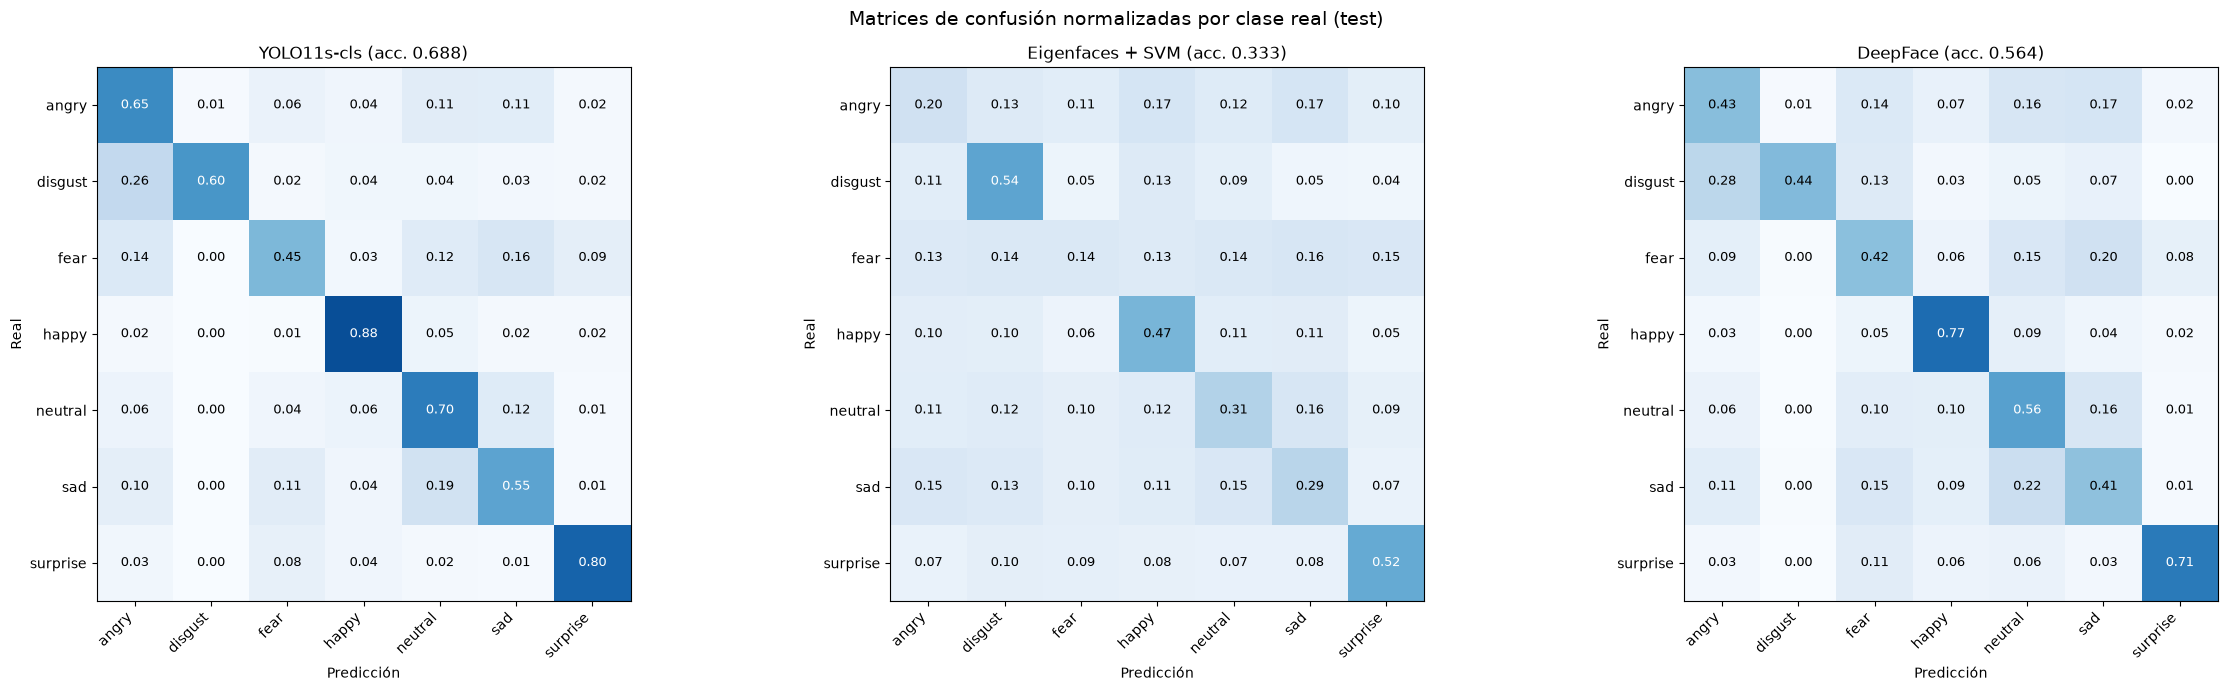

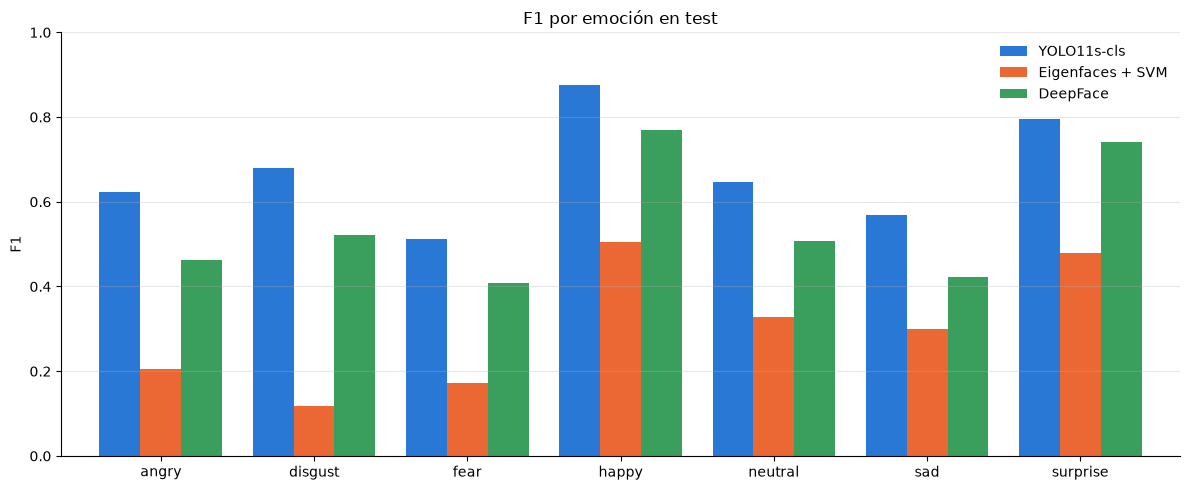

,YOLO11s-cls,Eigenfaces + SVM,DeepFace
angry,0.622,0.204,0.462
disgust,0.680,0.118,0.521
fear,0.511,0.173,0.408
happy,0.877,0.506,0.769
neutral,0.647,0.328,0.508
sad,0.569,0.301,0.422
surprise,0.795,0.478,0.741


In [4]:
# ===== C.2.2 Tabla comparativa, matrices de confusión y F1 por emoción =====
comparacion = pd.DataFrame(
    {m: [accuracy_score(Yte, preds[m]),
         precision_score(Yte, preds[m], average="macro"),
         recall_score(Yte, preds[m], average="macro"),
         f1_score(Yte, preds[m], average="macro"),
         ms_img[m]] for m in MODELOS},
    index=["Accuracy", "Precisión (macro)", "Recall (macro)", "F1 (macro)", "ms / imagen"],
).round(3)
display(comparacion)

# --- Matrices de confusión normalizadas por clase real ---
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, m in zip(axes, MODELOS):
    cm = confusion_matrix(Yte, preds[m], labels=range(len(CLASES)), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(CLASES)), CLASES, rotation=45, ha="right")
    ax.set_yticks(range(len(CLASES)), CLASES)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.set_title(f"{m} (acc. {accuracy_score(Yte, preds[m]):.3f})")
fig.suptitle("Matrices de confusión normalizadas por clase real (test)", fontsize=14)
plt.tight_layout()
plt.show()

# --- F1 por emoción ---
f1_clase = pd.DataFrame({m: f1_score(Yte, preds[m], average=None, labels=range(len(CLASES))) for m in MODELOS},
                        index=CLASES)
COLORES = ["#2a78d6", "#eb6834", "#3a9e5c"]
ax = f1_clase.plot.bar(figsize=(12, 5), color=COLORES, width=0.8, rot=0)
ax.set_ylabel("F1")
ax.set_ylim(0, 1)
ax.set_title("F1 por emoción en test")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
display(f1_clase.round(3))

#### Conclusiones de la evaluación en test

Resultados obtenidos al ejecutar C.2 (7.178 imágenes, GPU para YOLO y DeepFace):

| | YOLO11s-cls | Eigenfaces + SVM | DeepFace |
|---|---|---|---|
| Accuracy | **0.688** | 0.333 | 0.564 |
| F1 (macro) | **0.672** | 0.301 | 0.547 |
| ms / imagen | **0.4** | 6.1 | 12.4 |

- **YOLO11s-cls es el mejor en todas las emociones** y también el más rápido, porque clasifica por lotes en GPU. Ojo: `dataset_emociones` no tiene carpeta `val`, así que Ultralytics usó **test como validación** para elegir `best.pt` (su mejor época tiene 0.689 en validación, el mismo valor). Su resultado es, por tanto, algo optimista.
- **DeepFace queda en una posición intermedia (≈56 %)**, lo esperable para la CNN pequeña de FER-2013 que usa. Tiene el mismo patrón de errores que YOLO: *happy* y *surprise* son fáciles, y *fear*, *sad* y *angry* se confunden entre sí. Es el más lento porque `analyze` repite el preprocesado en cada llamada.
- **Eigenfaces + SVM (≈33 %) está muy por debajo**. PCA compara píxeles en bruto, así que capta sobre todo la iluminación, la pose y la identidad, y no los pequeños cambios de boca, cejas y ojos que definen una emoción. El `class_weight='balanced'` hace que prediga *disgust* demasiadas veces (recall 0.54, pero precisión 0.07).
- Recordatorio: DeepFace también se entrenó con FER-2013, así que su cifra en test puede estar algo inflada. La demo con webcam (C.3) mide cómo se generaliza cada modelo a caras nuevas.

## C.3 Comparativa en tiempo real con la webcam

En cada frame:
1. **YOLO11s** detecta la cara (el mismo detector para los tres, así solo cambia el clasificador).
2. Se toma un **recorte cuadrado** centrado en la caja, igual que en la demo de eigenfaces. FER-2013 tiene caras cuadradas, y así ninguna entrada se deforma.
3. El **mismo recorte** pasa a los tres modelos, y en pantalla se muestra la predicción de cada uno con su confianza y su tiempo.

**Modo etiquetado:** si se pulsa una tecla `1`–`7` se fija la emoción que se está poniendo (la leyenda está en pantalla). A partir de ahí, cada frame se guarda con esa etiqueta y las predicciones se pintan en **verde** si aciertan y en **rojo** si fallan. Con `0` se quita la etiqueta. Al salir, la celda siguiente calcula el acierto de cada modelo con tus caras.

- `1`–`7`: fijar emoción real · `0`: quitar etiqueta · `ESC`: salir
- `DEEPFACE_CADA`: si va lento, DeepFace se ejecuta solo cada N frames y en los demás se repite su última predicción.

In [5]:
# ===== C.3.1 Demo en tiempo real: los tres clasificadores sobre la misma cara =====
CAMARA = 1            # Índice preferido de la webcam (si no da imagen se prueban los demás)
DEEPFACE_CADA = 1     # Ejecuta DeepFace cada N frames (subir si va lento)
MARGEN = 0.0          # Margen extra alrededor de la caja de YOLO (0.1 = 10 % más grande)

TECLAS = {ord(str(i + 1)): c for i, c in enumerate(CLASES)}          # '1' -> angry, '2' -> disgust...
LEYENDA = "  ".join(f"{i + 1}:{c}" for i, c in enumerate(CLASES))


def recorte_cuadrado(img, x1, y1, x2, y2, margen=MARGEN):
    """Caja cuadrada centrada en la detección (las caras de FER-2013 son cuadradas)."""
    h_img, w_img = img.shape[:2]
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    lado = max(x2 - x1, y2 - y1) * (1 + margen)
    a1, b1 = int(max(cx - lado / 2, 0)), int(max(cy - lado / 2, 0))
    a2, b2 = int(min(cx + lado / 2, w_img)), int(min(cy + lado / 2, h_img))
    return img[b1:b2, a1:a2]


registro = []                                          # Una fila por frame con cara
ultimo = {m: ("-", None, 0.0) for m in MODELOS}        # Última (emoción, confianza, ms) de cada modelo
etiqueta_real = None
n_frame = 0

vid = abrir_camara(CAMARA)
while True:
    ret, img = vid.read()
    if not ret:
        print("No se ha podido leer un frame de la cámara")
        break
    h_img, w_img = img.shape[:2]

    faces = detector(img, verbose=False)[0]
    hay_cara = False
    if len(faces.boxes) > 0:
        x1, y1, x2, y2 = faces.boxes.xyxy[0].int().tolist()
        cara = recorte_cuadrado(img, x1, y1, x2, y2)
        if cara.size > 0:
            hay_cara = True
            fila = {"etiqueta": etiqueta_real}
            for nombre, predecir in PREDICTORES.items():
                ms = np.nan
                if nombre != "DeepFace" or n_frame % DEEPFACE_CADA == 0:
                    t0 = perf_counter()
                    (y,), (conf,) = predecir([cara])
                    ms = 1000 * (perf_counter() - t0)
                    ultimo[nombre] = (CLASES[y], conf, ms)
                fila[nombre] = ultimo[nombre][0]
                fila[f"ms {nombre}"] = ms
            registro.append(fila)
            n_frame += 1
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 255), 2)

    # --- Panel con la predicción de cada modelo ---
    for k, nombre in enumerate(MODELOS):
        emo, conf, ms = ultimo[nombre]
        texto = f"{nombre}: {emo}" + (f" {conf:.2f}" if conf is not None else "") + f"  ({ms:.0f} ms)"
        if not hay_cara:
            color = (160, 160, 160)                                  # Gris: predicción del último frame con cara
        elif etiqueta_real is None:
            color = (255, 255, 255)
        else:
            color = (0, 255, 0) if emo == etiqueta_real else (0, 0, 255)
        dibujar_texto(img, texto, (10, 30 + 30 * k), color, 0.7)
    if not hay_cara:
        dibujar_texto(img, "Sin cara", (10, 30 + 30 * len(MODELOS)), (0, 165, 255), 0.7)

    dibujar_texto(img, LEYENDA, (10, h_img - 40), (255, 255, 255), 0.45)
    dibujar_texto(img, f"Real: {etiqueta_real or '-'}   [1-7] fijar  [0] quitar  [ESC] salir"
                       f"   frames etiquetados: {sum(f['etiqueta'] is not None for f in registro)}",
                  (10, h_img - 15), (255, 255, 0), 0.5)
    cv2.imshow("Comparativa de emociones: YOLO11s-cls / Eigenfaces + SVM / DeepFace", img)

    tecla = cv2.waitKey(1) & 0xFF
    if tecla == 27:  # Esc para salir
        break
    elif tecla in TECLAS:
        etiqueta_real = TECLAS[tecla]
    elif tecla == ord("0"):
        etiqueta_real = None

vid.release()
cv2.destroyAllWindows()
registro = pd.DataFrame(registro)
print(f"Frames con cara: {len(registro)}")

Cámara abierta: índice 1
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32, updating to [64]
WARNING imgsz=[48] must be multiple of max stride 32

Frames con cara: 457  |  etiquetados: 0


,Accuracy (frames etiquetados),ms / cara (media),FPS máx. solo con este modelo
YOLO11s-cls,NaN,15.824,63.196
Eigenfaces + SVM,NaN,8.423,118.717
DeepFace,NaN,15.663,63.846


Acuerdo entre modelos (todos los frames con cara):


,YOLO11s-cls,Eigenfaces + SVM,DeepFace
YOLO11s-cls,1.000,0.186,0.689
Eigenfaces + SVM,0.186,1.000,0.385
DeepFace,0.689,0.385,1.000


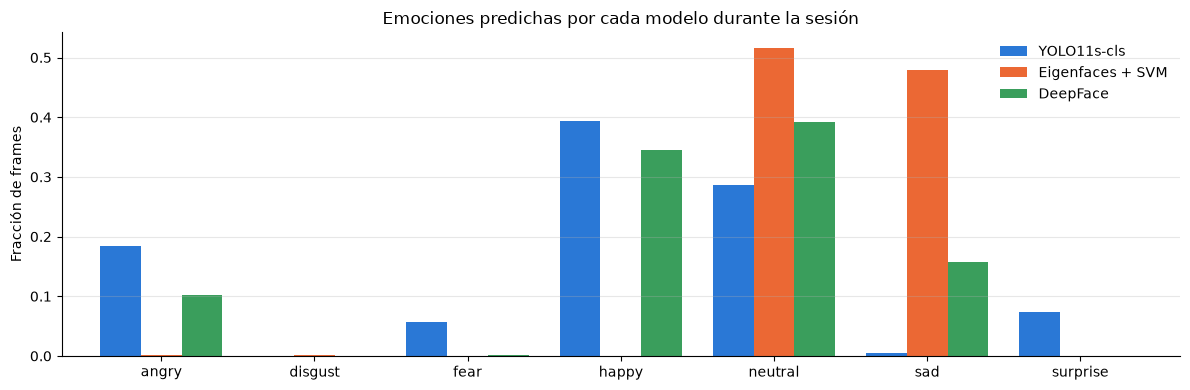

: 

In [ ]:
# ===== C.3.2 Resultados de la sesión con webcam =====
if len(registro) == 0:
    print("No se ha registrado ningún frame con cara: ejecuta antes la demo (C.3.1)")
else:
    etiq = registro[registro["etiqueta"].notna()]
    print(f"Frames con cara: {len(registro)}  |  etiquetados: {len(etiq)}")

    resumen = pd.DataFrame({
        "Accuracy (frames etiquetados)": [(etiq[m] == etiq["etiqueta"]).mean() if len(etiq) else np.nan
                                          for m in MODELOS],
        "ms / cara (media)": [registro[f"ms {m}"].mean() for m in MODELOS],
        "FPS máx. solo con este modelo": [1000 / registro[f"ms {m}"].mean() for m in MODELOS],
    }, index=MODELOS).round(3)
    display(resumen)

    # Acierto por emoción (solo de las emociones que se han etiquetado)
    if len(etiq):
        por_emocion = pd.DataFrame(
            {emo: {**{m: (d[m] == emo).mean() for m in MODELOS}, "frames": len(d)}
             for emo, d in etiq.groupby("etiqueta")}
        ).T.reindex([c for c in CLASES if c in set(etiq["etiqueta"])])
        print("Acierto por emoción real:")
        display(por_emocion.round(3))

    # Acuerdo entre modelos: % de frames en que dos modelos predicen la misma emoción (no necesita etiqueta)
    acuerdo = pd.DataFrame([[(registro[a] == registro[b]).mean() for b in MODELOS] for a in MODELOS],
                           index=MODELOS, columns=MODELOS).round(3)
    print("Acuerdo entre modelos (todos los frames con cara):")
    display(acuerdo)

    # Distribución de emociones que predice cada modelo
    distrib = pd.DataFrame({m: registro[m].value_counts(normalize=True) for m in MODELOS}).reindex(CLASES).fillna(0)
    ax = distrib.plot.bar(figsize=(12, 4), color=["#2a78d6", "#eb6834", "#3a9e5c"], width=0.8, rot=0)
    ax.set_ylabel("Fracción de frames")
    ax.set_title("Emociones predichas por cada modelo durante la sesión")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()